# {The Relationship Between Educational Achievements and Quality of Life in Rural Nepal}📝

![Banner](./assets/banner.jpeg)

## Education and Quality of Life in Rural Communities in Nepal
*What problem are you (or your stakeholder) trying to address?*
📝 <!-- Answer Below -->
The problem I want to look into is whether there is a correlation between educational achievements and the quality of life in rural communities in Nepal. In the rural communities, many families have difficulty with poverty, hard land, and limited schools. There are government groups and non-profit organizations that help out money towards education, hoping that it will help lead to a better life for families. But we do not really know whether going to school is leading people to a better life in rural areas, like higher wealth, better jobs, or basic needs.

## Project Question
*What specific question are you seeking to answer with this project? This is not the same as the questions you ask to limit the scope of the project. 📝* <!-- Answer Below -->

Is higher educational achievement associated with employment status among adults in rural Nepal?
Which quality of life factor has the strongest relationship with educational achievement?
Is educational achievement associated with access to basic household services?
How does household wealth vary across different levels of educational achievement?

## What would an answer look like?
*What is your hypothesized answer to your question?*
📝 <!-- Answer Below -->
I plan to use charts and statistics to answer my questions. 

For the relationship between household wealth and educational achievement, I can create a boxplot/scatter plot. This can show whether households with higher educational achievement have different wealth levels.

For education and employment, I can create a grouped bar chart that compares the percentage of working adults in different employment types.

For education and access to basic services, I will create a stacked bar chart that compares the percentage of the different education groups to their access to electricity, drinking water, or sanitation.

## Data Sources
*What 3 data sources have you identified for this project?*
*How are you going to relate these datasets?*
📝 <!-- Answer Below -->
1. Nepal Demographic and Health Survey (2022) - This is the main dataset for education, household wealth, location, employment, and household services.
2. World Bank Data - Helps support information on education, employment, and poverty.
3. UNESCO Institute for Statistics - Supports education and educational achievement data.

The DHS data contains household information for each individual, while the World Bank and UNESCO datasets contain national-level economic and education indicators. I will aggregate the DHS household data by year (2022) and region, and connect the regional average to the World Bank and UNESCO datasets by year(2022) and country (Nepal) as the matching key.

In [2]:
import pandas as pd
import urllib.request
import json


# SOURCE 1: Local Microdata File (.DTA)

dhs = pd.read_stata(
    r"C:\Users\reshi\OneDrive\Desktop\Fall 2026\Data Tech Analytics\NPPR82FL.DTA"
)


# SOURCE 2: API Import (World Bank API via urllib)

wb_url = ("https://api.worldbank.org/v2/country/NPL/indicator"
            "/NY.GDP.PCAP.CD?date=2015:2022&format=json")
with urllib.request.urlopen(wb_url,timeout=30) as repsonse:
    wb_data = json.loads(repsonse.read().decode('utf-8'))[1]

worldbank_df = pd.DataFrame(wb_data)[['date', 'value']].rename(
    columns={'value': 'gdp_per_capita'})


# SOURCE 3: Web-Scraped / JSON Endpoint Data (UNESCO/SDG Indicator Data via urllib)

# Pulling SDG 4 / Education indicator JSON directly from web source
unesco_api_url = ("http://api.worldbank.org/v2/country/NPL/indicator"
                    "/SE.PRM.CMPT.ZS?date=2015:2022&format=json")
with urllib.request.urlopen(unesco_api_url, timeout=30) as repsonse:
    unesco_reponse =json.loads(repsonse.read().decode("utf-8"))
unesco_data =unesco_reponse[1]

unesco_df = pd.DataFrame(unesco_data)[['date', 'value']].rename(
    columns={
        "date": "year",
        'value': "primary_completion_rate"})

unesco_df["year"] = pd.to_numeric(
    unesco_df["year"], errors="coerce"
)

unesco_df["primary_completion_rate"]= pd.to_numeric(
    unesco_df["primary_completion_rate"],errors="coerce"
)
unesco_data=unesco_df.sort_values("year").reset_index(drop=True)

# Check all 3 distinct source operations

print("1. DHS File Shape:", dhs.shape)
print("2. World Bank API Shape:", worldbank_df.shape)
print("3. UNESCO / SDG Web Data Shape:", unesco_df.shape)

1. DHS File Shape: (57278, 486)
2. World Bank API Shape: (8, 2)
3. UNESCO / SDG Web Data Shape: (8, 2)


In [6]:
## Data Inspection

#DHS dataset
print("DHS first five rows:")
display(dhs.head())

print("\nDHS dimensions:")
print(dhs.shape)

print("\nDHS data types:")
print(dhs.dtypes.value_counts())

#World Bank GDP dataset
print("\nWorld Bank GDP Data:")
display(worldbank_df)


#World bank main completion dataset
print("\nUNESCO sourced Priamry Completion Dataset:")
display(unesco_df)

DHS first five rows:


,hhid,hvidx,hv000,hv001,hv002,hv003,hv004,hv005,hv006,hv007,...,hai13i,hai13j,hai13k,hai13l,hai13m,hai13n,hai13o,hai13p,hai13x,hai13z
0,1 1,1,NP8,1,1,1,1,934601,magh,2078,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1 1,2,NP8,1,1,1,1,934601,magh,2078,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1 1,3,NP8,1,1,1,1,934601,magh,2078,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1 1,4,NP8,1,1,1,1,934601,magh,2078,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1 1,5,NP8,1,1,1,1,934601,magh,2078,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



DHS dimensions:
(57278, 486)

DHS data types:
category    94
category    65
float64     50
category    22
int8        15
            ..
category     1
category     1
category     1
category     1
category     1
Name: count, Length: 174, dtype: int64

World Bank GDP Data:


,date,gdp_per_capita
0,2022,1385.910660
1,2021,1252.750767
2,2020,1154.215176
3,2019,1203.142947
4,2018,1179.198432
5,2017,1034.283749
6,2016,877.256455
7,2015,875.543635



UNESCO sourced Priamry Completion Dataset:


,year,primary_completion_rate
0,2022,101.509212
1,2021,101.089346
2,2020,NaN
3,2019,118.470123
4,2018,NaN
5,2017,114.999534
6,2016,118.090019
7,2015,112.280647


In [12]:
#MissinG Values in DHS dataset
missing_count=dhs.isna().sum().sum()
total_cells = dhs.shape[0]* dhs.shape[1]
missing_percentage=(missing_count /total_cells)* 100

print("Total missinf DHS cells:",missing_count)
print("Total DHS cells:",total_cells)
print(f"Overall missingness:{missing_percentage:2f}%")

#No data columns
empty_columns = dhs.columns[dhs.isna().all()].tolist()
print("Empty Columnss:",len(empty_columns))

#Duplicate Rows
print("Duplicate Rowsa:",dhs.duplicated().sum())

#Check imporant columns
important_columns=[
    "hv025","hv106","hv107","hv270",
    "hv271","hv201","hv206"
]
for column in important_columns:
    if column in dhs.columns:
        print(f"\n{column}value counts:")
        display(dhs[column].value_counts(dropna=False).head(15))

Total missinf DHS cells: 16764118
Total DHS cells: 27837108
Overall missingness:60.222197%
Empty Columnss: 76
Duplicate Rowsa: 0

hv025value counts:


hv025
urban    29810
rural    27468
Name: count, dtype: int64


hv106value counts:


hv106
basic                                                24366
no education, preschool/early childhood education    14309
secondary                                            12422
NaN                                                   4562
higher                                                1546
don't know                                              73
Name: count, dtype: int64


hv107value counts:


...

hv271
-158851    26
 4516      22
-14081     21
-58387     21
 56555     20
 75675     18
-43787     18
 95117     18
 40826     17
 7602      17
 26264     17
 33551     17
-9009      17
 122436    17
-4640      16
Name: count, dtype: int64


hv201value counts:


hv201
piped to yard/plot                                      22193
tube well or borehole                                   19003
public tap/standpipe                                     6596
piped into dwelling                                      3471
bottled water                                            2181
protected spring                                         1071
piped to neighbor                                        1014
unprotected spring                                        742
unprotected well                                          415
protected well                                            392
river/dam/lake/ponds/stream/canal/irrigation channel      166
tanker truck                                               31
other                                                       3
Name: count, dtype: int64


hv206value counts:


hv206
yes    54218
no      3060
Name: count, dtype: int64

## Exploratory Data Analysis (EDA)

The purpose of EDA is to understand the Nepal Demographic and Health Survey (DHDS) dataset and identify any patterns between educational achievement and quality-of-life indicators in rural Nepal. I will inspect the distribution of education, household wealth, electricity access, and drinking water sources. I will look into the missing values, duplicate records, abnormalities, and data types that need attention,

The DHS is my primary source of demographic and household information. The World Bank indicator will support the context about Nepal's economic and education conditions. Because these data represent different levels of information, the indicator will be analyzed separately from individual DHS records.

In [17]:
## Rural Dataset

import matplotlib.pyplot as plt
import seaborn as sns

# Create temporary dataset for EDA
eda_df=dhs.copy()

#Remove columns with no data
eda_df =eda_df.dropna(axis=1,how="all")


# Check residence labels 
print("Residence type value:")
display(eda_df["hv025"].value_counts(dropna=False))

print("\nEducation level values:")
display(eda_df["hv106"].value_counts(dropna=False))

#Keeping rural records
rural_eda = eda_df[
    eda_df["hv025"].astype(str).str.strip().str.lower() == "rural"
].copy()

print("\nRural dataset shape:",rural_eda.shape)


# Rename columns
rename_columns={
    "hv025": "residence_type",
    "hv106": "education_level",
    "hv107": "education_grade",
    "hv270": "wealth_index_category",
    "hv271": "wealth_index_score",
    "hv201": "drinking_water_source",
    "hv206": "electricity_access"
}
rural_eda =rural_eda.rename(columns={
    old: new for old, new in rename_columns.items()
    if old in rural_eda.columns
})

# Scale wealth index score
rural_eda["wealth_index_score_scaled"]=(
    rural_eda["wealth_index_score"] /100000
)
print("Rural dataset shape:", rural_eda.shape)
display(rural_eda.head())

Residence type value:


hv025
urban    29810
rural    27468
Name: count, dtype: int64


Education level values:


hv106
basic                                                24366
no education, preschool/early childhood education    14309
secondary                                            12422
NaN                                                   4562
higher                                                1546
don't know                                              73
Name: count, dtype: int64


Rural dataset shape: (27468, 410)
Rural dataset shape: (27468, 411)


,hhid,hvidx,hv000,hv001,hv002,hv003,hv004,hv005,hv006,hv007,...,hai13c,hai13d,hai13e,hai13f,hai13g,hai13h,hai13i,hai13x,hai13z,wealth_index_score_scaled
0,1 1,1,NP8,1,1,1,1,934601,magh,2078,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-1.0456
1,1 1,2,NP8,1,1,1,1,934601,magh,2078,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-1.0456
2,1 1,3,NP8,1,1,1,1,934601,magh,2078,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-1.0456
3,1 1,4,NP8,1,1,1,1,934601,magh,2078,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-1.0456
4,1 1,5,NP8,1,1,1,1,934601,magh,2078,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-1.0456


## 1. Exploratory Data Analysis (EDA)

1. Insights and Distribution

In the rural dataset, the largest category was basic education with 12,138 records. I explored whether there was any relation between education and household wealth, electricity access, and drinking water using visualization. 

2. Correlations 

The chart showed the relationship between education achievement and living conditions.

3. Outliers or Data issues

I had to remove 76 empty columns. The weight score has both negative and positive values. I have not identified any outliers.

4. Missing Values

Education level has 2,270 missing records in the rural dataset, and education grade has 9,628 missing records. I excluded missing and unknown education.

5. Duplicates 

There were no exact duplicate rows. It is expected to have multiple house IDs because a household can contain multiple records.

6. Data types

I have renamed the important variables for clarity and scaled the wealth score by dividing it by 100,00. 

<function matplotlib.pyplot.show(close=None, block=None)>

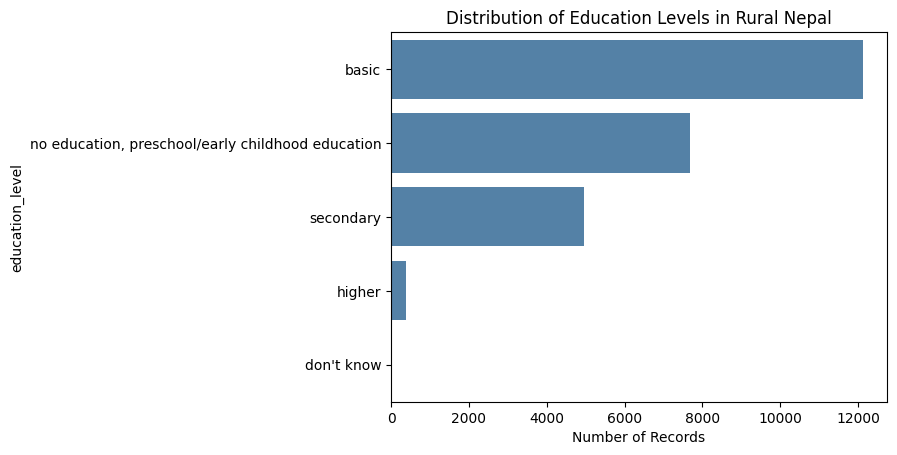

In [21]:
# Visualization 1: Education-Level Distribution in Rural Nepal

education_data=rural_eda[
    rural_eda["education_level"].notna()
].copy()
plt.Figure(figsize=(10,6))

sns.countplot(
    data=education_data,
    y="education_level",
    order=education_data["education_level"].value_counts().index,
    color="steelblue"
)

plt.title("Distribution of Education Levels in Rural Nepal")
plt.xlabel("Number of Records")
plt.ylabel("education_level")

plt.tight_layout
plt.show

Visualization 1: Education-Level Distribution in Rural Nepal


This bar chart shows the distribution of education level within rural Nepal. The chart helps show which education level is the most common and which is less represented. Records that do not have missing education level values are excluded. This is the starting point to examine whether there is a correlation with education achievement and household health and access to basic services.

<function matplotlib.pyplot.show(close=None, block=None)>

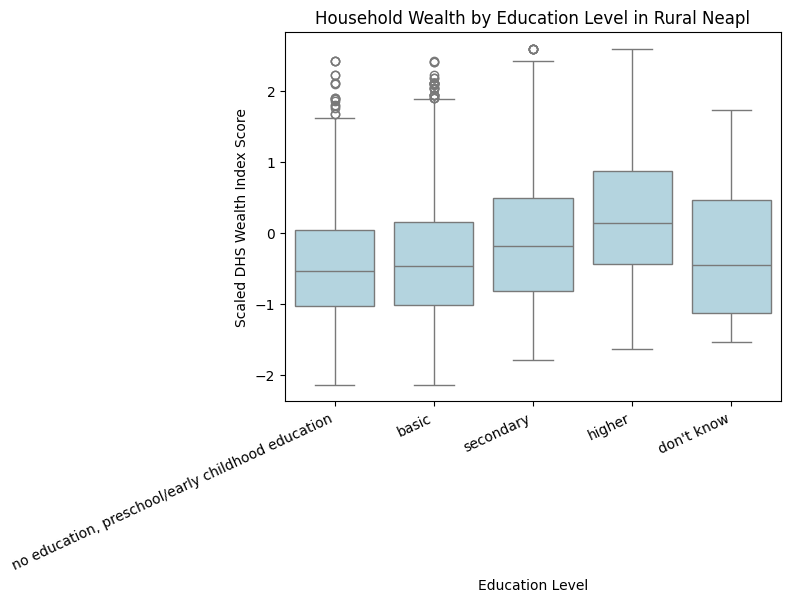

In [24]:
# Visualization 2: Household Wealth by Education Level

wealth_plot_df=rural_eda[
    rural_eda["education_level"].notna()
    & rural_eda["wealth_index_score_scaled"].notna()
].copy()

plt.Figure(figsize=(11,6))
sns.boxplot(
    data=wealth_plot_df,
    x="education_level",
    y="wealth_index_score_scaled",
    color="lightblue"
)

plt.title("Household Wealth by Education Level in Rural Neapl")
plt.xlabel("Education Level")
plt.ylabel("Scaled DHS Wealth Index Score")
plt.xticks(rotation=25, ha="right")
plt.tight_layout
plt.show

Visualization 2: Household Wealth by Education Level

This boxplot compares the wealth index based on education achievement in rural Nepal. This shows the difference in each category in the median wealth score. The boxplots show that the higher the education, the higher the wealth index.

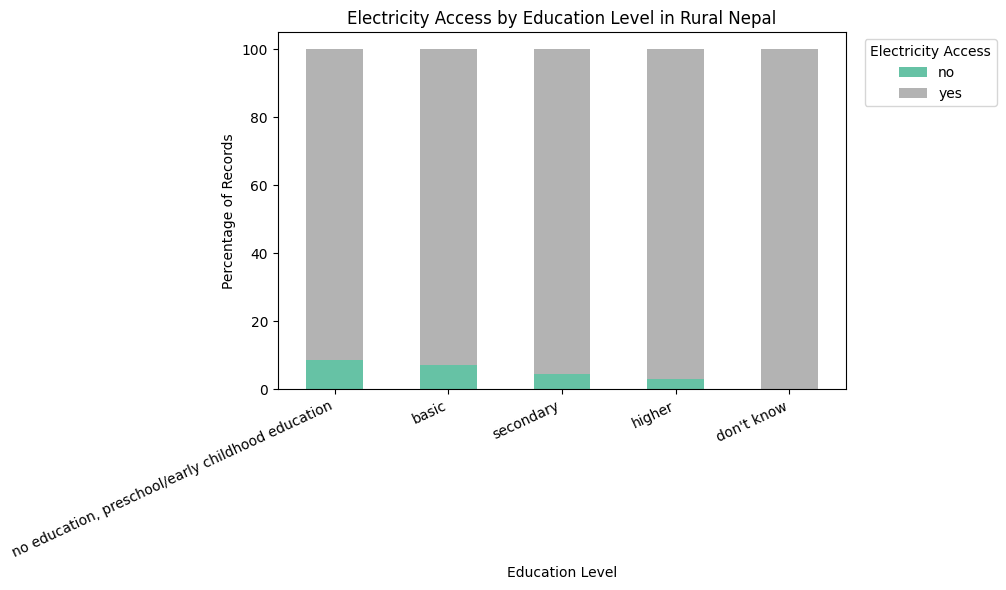

In [25]:
# Visualization 3: Electricity Access by Education Level

electricity_df =rural_eda[
    rural_eda["education_level"].notna()
    & rural_eda["electricity_access"].notna()
].copy()

electricity_pct =pd.crosstab(
    electricity_df["education_level"],
    electricity_df["electricity_access"],
    normalize="index"
)*100

ax=electricity_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(10,6),
    colormap="Set2"
)

ax.set_title("Electricity Access by Education Level in Rural Nepal")
ax.set_xlabel("Education Level")
ax.set_ylabel("Percentage of Records")
ax.legend(
    title="Electricity Access",
    bbox_to_anchor=(1.02,1),
    loc="upper left"
)

plt.xticks(rotation=25,ha="right")
plt.tight_layout()
plt.show()

Visualization 3: Electricity Access by Education Level

The stacked bar chart compares electricity access across all education level categories in rural Nepal. The percentages show the proportion with and without electricity in each group. The visualization shows that the higher the education, the greater the electricity access they received.

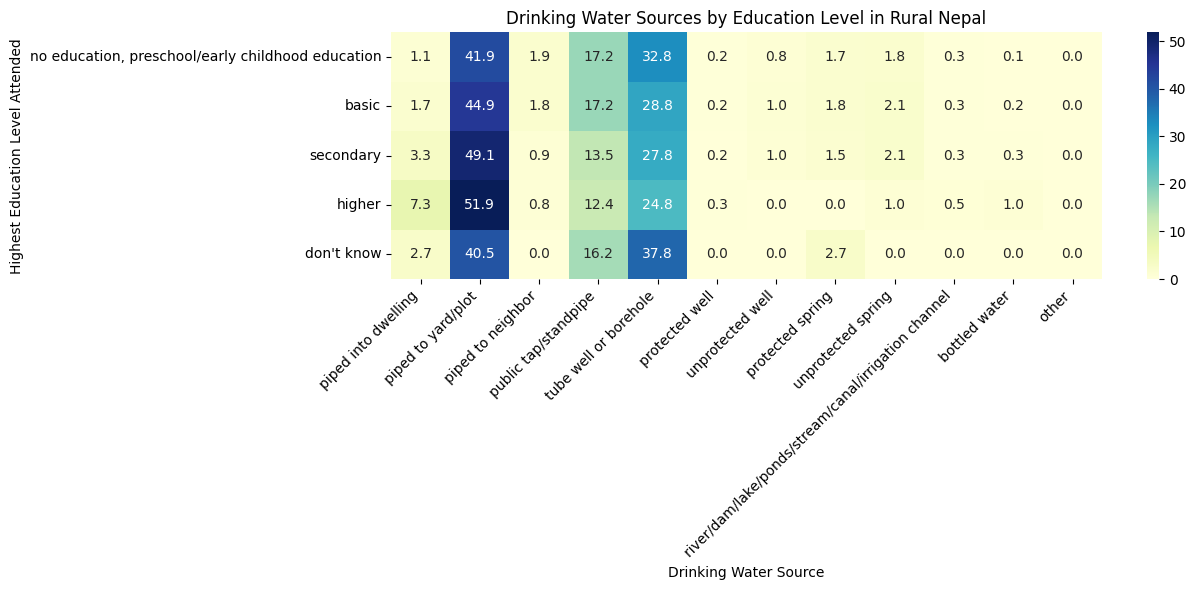

In [39]:
# Visualization 4: Drinking Water Sources by Education Level
water_df=rural_eda[
    rural_eda["education_level"].notna()
    &rural_eda["drinking_water_source"].notna()
]

water_pct = pd.crosstab(
    water_df["education_level"],
    water_df["drinking_water_source"],
    normalize="index"
)*100

plt.figure(figsize=(13, 6))

sns.heatmap(
    water_pct,
    cmap="YlGnBu",
    annot=True,
    fmt=".1f"
)

plt.title("Drinking Water Sources by Education Level in Rural Nepal")
plt.xlabel("Drinking Water Source")
plt.ylabel("Highest Education Level Attended")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 2. Data Cleaning 
In this section, I have prepared the Nepal DHS 2022 data for analysis. I noticed that there were missing values, duplicate records, unusual values, and data type issues. I removed columns that had no data, checked for duplicate records, cleaned up variable names, and prepared a subset of rural records for the reach questions. Rather than automatically replacing or deleting scores, I maintained the missing values and usual records. These cleaning decisions improved the consistency of the data while maintaining the information.

In [44]:
# 2.1 Create a copy and removed empty columns

dhs_clean=dhs.copy()

print("Original dataset shape:",dhs_clean.shape)

dhs_clean=dhs_clean.dropna(axis=1,how="all")
print("Shape after removing empty columns:",dhs_clean.shape)

duplicate_count=dhs_clean.duplicated().sum()
print("Duplicate rows:",duplicate_count)

important_columns=[
    "hv025","hv106","hv107","hv270",
    "hv271","hv201","hv206"
]
print("\nMissing values in importnat columns")
for column in important_columns:
    if column in dhs_clean.columns:
            missing_count=dhs_clean[column].isna().sum()
            print(f"{column}:{missing_count:,} missing values"
        ) 
    else:
       print(f"{column}:Column not found")   

Original dataset shape: (57278, 486)
Shape after removing empty columns: (57278, 410)
Duplicate rows: 0

Missing values in importnat columns
hv025:0 missing values
hv106:4,562 missing values
hv107:18,288 missing values
hv270:0 missing values
hv271:0 missing values
hv201:0 missing values
hv206:0 missing values


In [64]:
# 2.2 Rename Variables and Scale Wealth Index
rename_columns = {
    "hv025":"residence_type",
    "hv106":"education_level",
    "hv107":"education_grade",
    "hv270": "wealth_index_category",
    "hv271": "wealth_index_score",
    "hv201": "drinking_water_source",
    "hv206": "electricity_access"
}

dhs_clean=dhs_clean.rename(
    columns=rename_columns
)

dhs_clean["wealth_index_score"]=dhs["hv271"]
dhs_clean["wealth_index_score_scaled"]=(
    pd.to_numeric(dhs["hv271"], 
                  errors="coerce") / 100000
  
)
print("Updated dataset shape:",dhs_clean.shape)

display(
    dhs_clean[
        [
        "residence_type",
        "education_level",
        "education_grade",
        "wealth_index_category",
        "wealth_index_score",
        "wealth_index_score_scaled",
        "drinking_water_source",
        "electricity_access"
        ]
    ].head()
)

Updated dataset shape: (57278, 411)


,residence_type,education_level,education_grade,wealth_index_category,wealth_index_score,wealth_index_score_scaled,drinking_water_source,electricity_access
0,rural,basic,8.0,poorest,-104560,-1.0456,piped to yard/plot,yes
1,rural,basic,8.0,poorest,-104560,-1.0456,piped to yard/plot,yes
2,rural,basic,4.0,poorest,-104560,-1.0456,piped to yard/plot,yes
3,rural,basic,0.0,poorest,-104560,-1.0456,piped to yard/plot,yes
4,rural,"no education, preschool/early childhood education",NaN,poorest,-104560,-1.0456,piped to yard/plot,yes


In [68]:
# 2.3 prepare rural dataset

rural_clean =dhs_clean[
    dhs_clean["residence_type"]=="rural"
].copy()

print("Rural dataset shape:",rural_clean.shape)
print("\nResidence type counts:")
display(rural_clean["residence_type"].value_counts())

rural_columns=[
    "education_level",
    "education_grade",
    "wealth_index_category",
    "wealth_index_score_scaled",
    "drinking_water_source",
    "electricity_access"
]
print("\nMissing Values in rural dataset:")
display(rural_clean[rural_columns].isna().sum())

Rural dataset shape: (27468, 411)

Residence type counts:


residence_type
rural    27468
urban        0
Name: count, dtype: int64


Missing Values in rural dataset:


education_level              2270
education_grade              9628
wealth_index_category           0
wealth_index_score_scaled       0
drinking_water_source           0
electricity_access              0
dtype: int64

In [69]:
## 2.4 Investigate Missing Edcuation Values

print("Education level counts:")
display(rural_clean["education_level"].value_counts(dropna=False))

print("\neducation grade summary:")
display(rural_clean["education_grade"].describe())

print("\n)Education grdae missing count:")
print(rural_clean["education_grade"].isna().sum())

print("\nMissingness Comparsion:")

display(
    pd.crosstab(
        rural_clean["education_level"].isna(),
        rural_clean["education_grade"].isna(),
        margins=True
    )
)

Education level counts:


education_level
basic                                                12138
no education, preschool/early childhood education     7677
secondary                                             4951
NaN                                                   2270
higher                                                 395
don't know                                              37
Name: count, dtype: int64


education grade summary:


count     17840.0
unique       10.0
top           1.0
freq       3894.0
Name: education_grade, dtype: float64


)Education grdae missing count:
9628

Missingness Comparsion:


education_grade,False,True,All
education_level,,,
False,17840,7358,25198
True,0,2270,2270
All,17840,9628,27468


In [75]:
# 2.5 Preapre date fro education level analysis

rural_eda=rural_clean[
    rural_clean["education_level"].notna()
].copy()

print("Originla rural dataset:",rural_clean.shape)
print("Education-level analysis dataset:", rural_eda.shape)

print("\nMissing Education level:")
print(rural_eda["education_level"].isna().sum())

print("\nEducation level categories:")
display(rural_eda["education_level"].value_counts())

Originla rural dataset: (27468, 411)
Education-level analysis dataset: (25198, 411)

Missing Education level:
0

Education level categories:


education_level
basic                                                12138
no education, preschool/early childhood education     7677
secondary                                             4951
higher                                                 395
don't know                                              37
Name: count, dtype: int64

In [77]:
#2.6 finally edcaution analysis dataset
rural_analysis=rural_clean[
    rural_clean["education_level"].notna()
    &(rural_clean["education_level"]!="don't know")
].copy()

print("Final Education analysis dataset:",rural_analysis.shape)

print("\nEducation level categories:")
display(rural_analysis["education_level"].value_counts())

print("\nMissing education levels:")
print(rural_analysis["education_level"].isna().sum())

Final Education analysis dataset: (25161, 411)

Education level categories:


education_level
basic                                                12138
no education, preschool/early childhood education     7677
secondary                                             4951
higher                                                 395
don't know                                               0
Name: count, dtype: int64


Missing education levels:
0


In [80]:
# 2.7 finally data check

print("Final analysis dataset shape:",rural_analysis.shape)

print("\nDuplicate rows:",rural_analysis.duplicated().sum())

analysis_column=[
    "education_level",
    "wealth_index_category",
    "wealth_index_score_scaled",
    "drinking_water_source",
    "electricity_access"
]

print("\nMissing values in analysis variables:")
display(rural_analysis[analysis_column].isna().sum())

print("\nScaled wealth index summary")
display(rural_analysis["wealth_index_score_scaled"].describe())

print("\nEdcuation level counts:")
display(rural_analysis["education_level"].value_counts())

Final analysis dataset shape: (25161, 411)

Duplicate rows: 0

Missing values in analysis variables:


education_level              0
wealth_index_category        0
wealth_index_score_scaled    0
drinking_water_source        0
electricity_access           0
dtype: int64


Scaled wealth index summary


count    25161.000000
mean        -0.357034
std          0.782679
min         -2.141000
25%         -0.987540
50%         -0.442040
75%          0.189650
max          2.598590
Name: wealth_index_score_scaled, dtype: float64


Edcuation level counts:


education_level
basic                                                12138
no education, preschool/early childhood education     7677
secondary                                             4951
higher                                                 395
don't know                                               0
Name: count, dtype: int64

## 3. Machine Learning Plan

3.1 What type of machine learning model are you planning to use?

I plan to use the decision tree classifier to dive more into the relationship between household living conditions and education level in rural Nepal. The model can help predict expected education level based on the household wealth score, drinking water, and electricity access.

3.2 What are the challenges have you identified/are you anticipating in building your machine learning model?

One main challenge is the missing data. Another would be that some education categories have more records than others. The dataset also contains multiple records with the same household.

3.3 How are you planning to address these challenges?

I plan to record unknown education levels and exclude the "don't know" from the model. I will change categorical variables to numerical values before training the model. I also plan to compare the model's accuracy with a baseline model using precision and recall to evaluate the predictions. If possible, I want to report the household identifier when splitting the data. Rather than seeing it as cause and effect, I will see the results as associations.

# 4. Prior Feedback and Updates

1. What feedback did you receive from your peers and/or the teaching team?

Based on the feedback I have received, I now think more carefully about organizing my dataset and handling missing values. It also made me realize how important it is to connect my EDA to my machine learning plan.

2. What changes have you made to your project based on this feedback?

I have removed empty columns, checked for duplicates, renamed variables, and created a separate dataset for rural households. I checked for missing values and created visualizations to better understand the correlations.

## Approach and Analysis
*What is your approach to answering your project question?*
*How will you use the identified data to answer your project question?*
📝 <!-- Start Discussing the project here; you can add as many code cells as you need -->
I will begin by cleaning and organizing the DHS 2022 data and filtering to focus more on rural households in Nepal. I plan to group participants by their education and compare household wealth, employment status, and access to basic services. I plan to use charts, correlations, and statistics to identify any trends, patterns, or relationships. The DHS will be my main dataset; the World Bank and UNESCO will be used to support the information.

In [1]:
# Start your code here

## Resources and References
*What resources and references have you used for this project?*
📝 <!-- Answer Below -->
1. DHS Program :https://dhsprogram.com/data/dataset_admin/index.cfm 
2. World Bank: https://data.worldbank.org/country/nepal 
3. UNESCO UIS: https://www.uis.unesco.org/en/data/sdg4-country-profiles? 

In [10]:
# ⚠️ Make sure you run this cell at the end of your notebook before every submission!
!jupyter nbconvert --to python source.ipynb

[NbConvertApp] Converting notebook source.ipynb to python
[NbConvertApp] Writing 5557 bytes to source.py
